# House Price Prediction — Audited & Reproducible Workflow

**Objective.** Predict the sale price (`SalePrice`, USD) of residential houses from 79 descriptive features, and evaluate honestly how well different regression models do it.

**What this notebook is.** A cleaned-up, audited and extended version of an earlier notebook (`finaltry (1).ipynb`) that used a single `LinearRegression` pipeline. The original idea (a `ColumnTransformer` + `Pipeline`, a 80/20 split with `random_state=42`, and a `log1p` target experiment) is **preserved and reproduced first** (Section 12) and then improved.

**Data.** `data/train.csv` (1,460 labelled houses) and `data/test.csv` (1,459 unlabelled houses). The column names and sizes match the public Ames-housing data used in the Kaggle *House Prices — Advanced Regression Techniques* competition, but the source of the files was not verified inside this project. `test.csv` has **no** `SalePrice`, so no test metrics can be computed; it is only used for the final predictions file.

**Principles followed throughout**
1. Original CSVs are never modified. Everything is derived in memory.
2. The train/validation split is made **once, before any target-based analysis**. Target-based EDA and every modelling decision use only the training part.
3. All preprocessing lives inside a scikit-learn `Pipeline`, so it is fitted on training rows only.
4. Every model is scored on the same validation rows and the same cross-validation folds.
5. No metric is typed in by hand — every number in this notebook comes from the executed code (except the *original* notebook's numbers, which are explicitly marked and re-computed for comparison).

## 1. Imports and Configuration

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42                      # one seed used everywhere
TEST_SIZE = 0.20               # same split as the original notebook
N_FOLDS = 5
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.3
numpy       : 2.4.4
pandas      : 3.0.2
scikit-learn: 1.8.0


### Paths
The notebook finds the project folder automatically, so it works from `notebooks/` locally or from a Colab session where `train.csv` / `test.csv` were uploaded next to the notebook (or into a `data/` folder).

In [2]:
def find_data_dir():
    for base in [Path.cwd(), Path.cwd().parent]:
        if (base / "data" / "train.csv").exists():
            return base / "data", base
    if (Path.cwd() / "train.csv").exists():             # e.g. Colab: files uploaded next to the notebook
        return Path.cwd(), Path.cwd()
    raise FileNotFoundError("train.csv not found. Put train.csv and test.csv in ./data or next to the notebook.")

DATA_DIR, ROOT = find_data_dir()
OUT_DIR, IMG_DIR = ROOT / "outputs", ROOT / "images"
OUT_DIR.mkdir(exist_ok=True); IMG_DIR.mkdir(exist_ok=True)
print("Data folder   :", DATA_DIR)
print("Outputs folder:", OUT_DIR)

def save_fig(name):
    plt.savefig(IMG_DIR / name, dpi=130, bbox_inches="tight")

Data folder   : /home/claude/House-Price-Prediction/data
Outputs folder: /home/claude/House-Price-Prediction/outputs


## 2. Dataset Loading

In [3]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")   # original file, never modified
test_raw  = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train_raw.shape, "| test:", test_raw.shape)

train: (1460, 81) | test: (1459, 80)


## 3. Initial Data Inspection

In [4]:
print("Dtypes in train:\n", train_raw.dtypes.astype(str).value_counts(), "\n")
print("Duplicate rows  train / test :", train_raw.duplicated().sum(), "/", test_raw.duplicated().sum())
print("Duplicate Ids   train / test :", train_raw["Id"].duplicated().sum(), "/", test_raw["Id"].duplicated().sum())
print("Id ranges       train / test :", (train_raw["Id"].min(), train_raw["Id"].max()), "/", (test_raw["Id"].min(), test_raw["Id"].max()))
print("Id overlap between train and test:", len(set(train_raw["Id"]) & set(test_raw["Id"])))

# Feature columns must match exactly (test has everything except the target)
assert list(test_raw.columns) == [c for c in train_raw.columns if c != "SalePrice"], "train/test columns differ"
print("\nTest columns == train columns minus SalePrice  ->  OK")
train_raw.head()

Dtypes in train:
 str        43
int64      35
float64     3
Name: count, dtype: int64 

Duplicate rows  train / test : 0 / 0
Duplicate Ids   train / test : 0 / 0
Id ranges       train / test : (np.int64(1), np.int64(1460)) / (np.int64(1461), np.int64(2919))
Id overlap between train and test: 0

Test columns == train columns minus SalePrice  ->  OK


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,...,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,...,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,...,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,...,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,...,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,...,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**Notes on the data's quirks.**
- `Id` is just a row label. It carries no information about the house, so it is **not** used as a feature (the original notebook accidentally fed it to the model as a number).
- `MSSubClass` is stored as a number (20, 30, 60, …) but these are *category codes* for the dwelling type, not quantities. It is converted to text so it is one-hot encoded instead of being scaled as if 60 were "three times" 20.
- In this dataset many `NaN`s are not "unknown": e.g. `GarageType = NaN` means *the house has no garage*. This is handled explicitly in Section 6.

## 4. Train / Validation Split
The split is created **now**, once, before any analysis that uses the target. The validation rows are not looked at again until models are scored. Same settings as the original notebook (`test_size=0.2`, `random_state=42`).

In [5]:
TARGET = "SalePrice"

def clean_types(df):
    # Stateless, deterministic clean-up applied identically to train and test.
    out = df.drop(columns=["Id", TARGET], errors="ignore").copy()
    out["MSSubClass"] = out["MSSubClass"].astype(str)      # category code, not a quantity
    return out

X_all = clean_types(train_raw)
y_all = train_raw[TARGET]
X_test = clean_types(test_raw)
test_ids = test_raw["Id"].copy()

X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=TEST_SIZE, random_state=SEED)
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test (unlabelled):", X_test.shape)
assert TARGET not in X_train.columns and "Id" not in X_train.columns

X_train: (1168, 79) | X_val: (292, 79) | X_test (unlabelled): (1459, 79)


## 5. Exploratory Data Analysis (training part only)

35 numeric and 44 categorical features

Most / least diverse categorical features (number of levels):
{'Neighborhood': 25, 'Exterior2nd': 16, 'Exterior1st': 15, 'MSSubClass': 15, 'Condition1': 9} ... {'Alley': 2, 'Street': 2, 'CentralAir': 2}


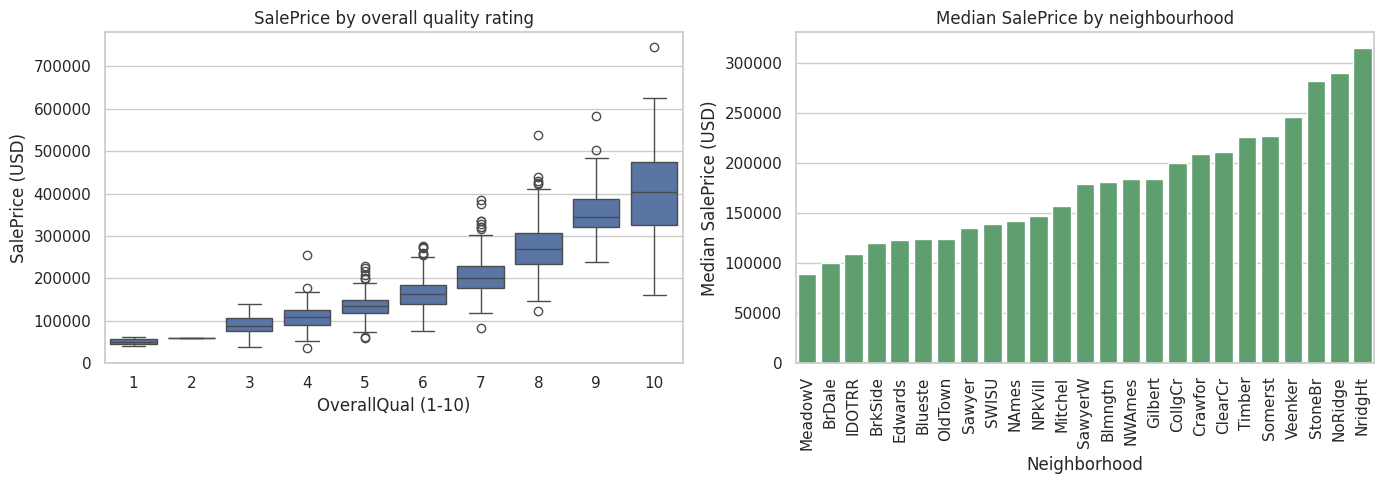

In [6]:
eda = X_train.assign(SalePrice=y_train)          # EDA frame: training rows only
num_cols_eda = eda.select_dtypes("number").columns.drop("SalePrice")
cat_cols_eda = eda.select_dtypes(exclude="number").columns
print(f"{len(num_cols_eda)} numeric and {len(cat_cols_eda)} categorical features")

cardinality = eda[cat_cols_eda].nunique().sort_values(ascending=False)
print("\nMost / least diverse categorical features (number of levels):")
print(cardinality.head(5).to_dict(), "...", cardinality.tail(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=eda, x="OverallQual", y="SalePrice", ax=axes[0], color="#4C72B0")
axes[0].set_title("SalePrice by overall quality rating"); axes[0].set_xlabel("OverallQual (1-10)"); axes[0].set_ylabel("SalePrice (USD)")
order = eda.groupby("Neighborhood")["SalePrice"].median().sort_values().index
sns.barplot(data=eda, x="Neighborhood", y="SalePrice", order=order, estimator=np.median, errorbar=None, ax=axes[1], color="#55A868")
axes[1].set_title("Median SalePrice by neighbourhood"); axes[1].set_ylabel("Median SalePrice (USD)")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout(); save_fig("01_eda_quality_neighborhood.png"); plt.show()

**Reading the plots.** Price rises steadily and non-linearly with `OverallQual`, and the spread widens at high quality. Neighbourhood also shifts the median price by a large amount. Both are signs that location and quality dominate, and that price variability is larger for expensive houses — an early hint that errors will be larger in dollars at the top of the market.

## 6. Missing Values Analysis
A missing value can mean two different things here: **the property does not exist** (no garage, no pool…) or **the value is genuinely unknown**. The data description for this dataset uses `NA` for the first meaning. I verify that interpretation against other columns instead of assuming it.

In [7]:
miss = pd.DataFrame({
    "train_missing_%": train_raw.drop(columns=TARGET).isna().mean() * 100,
    "test_missing_%":  test_raw.isna().mean() * 100,
})
miss = miss[(miss > 0).any(axis=1)].sort_values("train_missing_%", ascending=False)
print(len(miss), "columns have missing values in train or test")

# Evidence for 'NaN = feature absent' (the related numeric size column should be 0)
d = train_raw
checks = {
    "GarageType NaN  -> GarageArea == 0":   (d.loc[d["GarageType"].isna(), "GarageArea"] == 0).mean(),
    "BsmtQual NaN    -> TotalBsmtSF == 0":  (d.loc[d["BsmtQual"].isna(), "TotalBsmtSF"] == 0).mean(),
    "PoolQC NaN      -> PoolArea == 0":     (d.loc[d["PoolQC"].isna(), "PoolArea"] == 0).mean(),
    "FireplaceQu NaN -> Fireplaces == 0":   (d.loc[d["FireplaceQu"].isna(), "Fireplaces"] == 0).mean(),
}
print("\nShare of rows where the evidence holds:")
for k, v in checks.items(): print(f"  {k:<38}{v:6.1%}")

34 columns have missing values in train or test

Share of rows where the evidence holds:
  GarageType NaN  -> GarageArea == 0    100.0%
  BsmtQual NaN    -> TotalBsmtSF == 0   100.0%
  PoolQC NaN      -> PoolArea == 0      100.0%
  FireplaceQu NaN -> Fireplaces == 0    100.0%


In [8]:
# Treatment rules (decided from the meaning of each feature, NOT from model performance)
ABSENCE_CAT = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
               "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
               "PoolQC", "Fence", "MiscFeature", "MasVnrType"]       # NaN = "None" (feature absent)
ZERO_FILL_NUM = ["MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
                 "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea"]   # NaN = 0 (feature absent)

def treatment(col):
    if col in ABSENCE_CAT:    return "categorical: NaN -> 'None' (absent)"
    if col in ZERO_FILL_NUM:  return "numeric: NaN -> 0 (absent)"
    if pd.api.types.is_numeric_dtype(train_raw[col]): return "numeric: median + missing-indicator (unknown)"
    return "categorical: most frequent (unknown)"

miss["treatment"] = [treatment(c) for c in miss.index]
miss

,train_missing_%,test_missing_%,treatment
PoolQC,99.52,99.79,categorical: NaN -> 'None' (absent)
MiscFeature,96.30,96.50,categorical: NaN -> 'None' (absent)
Alley,93.77,92.67,categorical: NaN -> 'None' (absent)
Fence,80.75,80.12,categorical: NaN -> 'None' (absent)
MasVnrType,59.73,61.27,categorical: NaN -> 'None' (absent)
FireplaceQu,47.26,50.03,categorical: NaN -> 'None' (absent)
LotFrontage,17.74,15.56,numeric: median + missing-indicator (unknown)
GarageYrBlt,5.55,5.35,numeric: median + missing-indicator (unknown)
GarageFinish,5.55,5.35,categorical: NaN -> 'None' (absent)
GarageCond,5.55,5.35,categorical: NaN -> 'None' (absent)


**Findings.** The "absent" interpretation is confirmed for garage, pool, fireplace and basement (the related size column is 0 whenever the quality column is `NaN`). The columns that are *genuinely unknown* are `LotFrontage` (the largest case), `GarageYrBlt` (undefined when there is no garage), `Electrical` and a handful of test-only gaps (`MSZoning`, `Utilities`, …). Unknown values are imputed with statistics learned from the **training rows only** (median / most frequent), and `LotFrontage` / `GarageYrBlt` also get a "was missing" indicator column so the model can learn that missingness itself may be informative.

`MasVnrType` caveat: pandas reads the legitimate text label `"None"` (= no masonry veneer, 864 houses) as `NaN`, mixed with 8 truly missing rows. Treating all of them as "None" is the sensible choice (864 of 872) and agrees with `MasVnrArea` being 0/NaN for them.

## 7. Target Variable Analysis

                          count       mean       std       min        25%  \
SalePrice (train part) 1,168.00 181,441.54 77,263.58 34,900.00 130,000.00   

                              50%        75%        max  
SalePrice (train part) 165,000.00 214,925.00 745,000.00  

Skewness raw: 1.74   |   skewness after log1p: 0.12


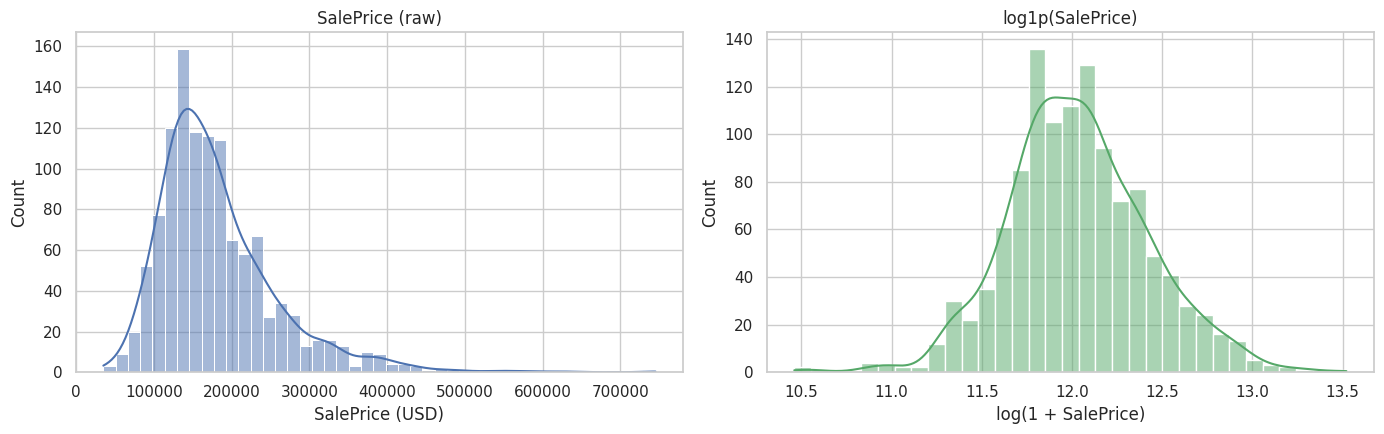

In [9]:
print(y_train.describe().to_frame("SalePrice (train part)").T)
print(f"\nSkewness raw: {y_train.skew():.2f}   |   skewness after log1p: {np.log1p(y_train).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(y_train, kde=True, ax=axes[0], color="#4C72B0"); axes[0].set_title("SalePrice (raw)"); axes[0].set_xlabel("SalePrice (USD)")
sns.histplot(np.log1p(y_train), kde=True, ax=axes[1], color="#55A868"); axes[1].set_title("log1p(SalePrice)"); axes[1].set_xlabel("log(1 + SalePrice)")
plt.tight_layout(); save_fig("02_target_distribution.png"); plt.show()

**Finding.** `SalePrice` is right-skewed (a long tail of expensive houses). After `log1p` the distribution is much closer to symmetric. This matters for linear models: they work best when errors are roughly symmetric and when a 10 % mistake costs the same whether the house is cheap or expensive. A log target turns the model into one that predicts *percentage* differences, which usually fits house prices better. This is a hypothesis to be **tested** in Section 13, not assumed.

## 8. Correlation Analysis

Top 10 numeric features by |Pearson correlation| with SalePrice (training part):
OverallQual    0.79
GrLivArea      0.70
GarageCars     0.64
GarageArea     0.62
TotalBsmtSF    0.60
1stFlrSF       0.59
FullBath       0.55
TotRmsAbvGrd   0.52
YearBuilt      0.52
YearRemodAdd   0.51


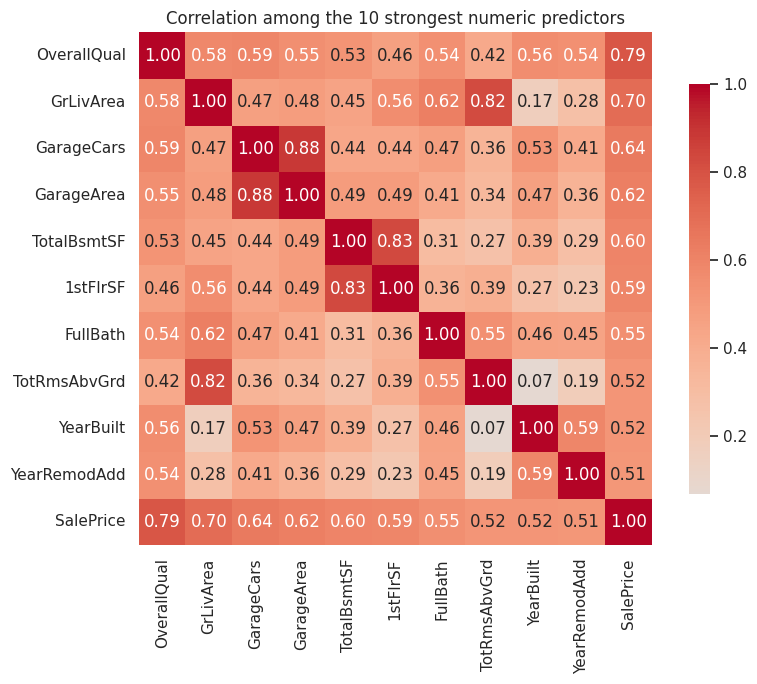

In [10]:
corr_with_price = eda.select_dtypes("number").corr()["SalePrice"].drop("SalePrice")
top = corr_with_price.abs().sort_values(ascending=False).head(10)
print("Top 10 numeric features by |Pearson correlation| with SalePrice (training part):")
print(corr_with_price[top.index].round(3).to_string())

top_cols = list(top.index) + ["SalePrice"]
plt.figure(figsize=(9, 7))
sns.heatmap(eda[top_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation among the 10 strongest numeric predictors"); plt.tight_layout()
save_fig("03_correlation_heatmap.png"); plt.show()

**Finding.** `OverallQual` and `GrLivArea` lead, followed by garage and basement size. Several predictors are strongly correlated **with each other** (e.g. `GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`). That is *multicollinearity*: it makes plain linear-regression coefficients unstable and is one reason a regularised model (Ridge) is worth testing. Correlation is not causation — these are associations in this data only.

## 9. Outlier Detection and Investigation
The original notebook computed IQR bounds on `SalePrice`. IQR flags *statistically unusual* values, which is not the same as *wrong* values. Here I first investigate what the flagged houses are, and only then consider treatment.

In [11]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

lo, hi = iqr_bounds(y_train)
price_flag = (y_train < lo) | (y_train > hi)
print(f"IQR bounds on SalePrice: [{lo:,.0f}, {hi:,.0f}] -> {price_flag.sum()} houses flagged ({price_flag.mean():.1%})")

profile = eda.assign(flag=price_flag).groupby("flag")[["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "YearBuilt"]].median()
profile.index = ["not flagged", "flagged by IQR"]
print("\nMedian profile of flagged vs not flagged houses:")
profile

IQR bounds on SalePrice: [2,612, 342,312] -> 48 houses flagged (4.1%)

Median profile of flagged vs not flagged houses:


,OverallQual,GrLivArea,TotalBsmtSF,GarageCars,YearBuilt
not flagged,6.00,"1,442.00",980.00,2.00,"1,971.00"
flagged by IQR,9.00,"2,362.00","1,852.00",3.00,"2,006.00"


**Finding.** The IQR-flagged houses are overwhelmingly high-priced houses that are also **larger and of higher quality** than typical houses. Their price is *explained by their features*. They are valid observations of the expensive end of the market — deleting them would make the model worse exactly where it must work. **They are not removed.**

The more specific question is whether any observation is *inconsistent with the rest of the relationship* — a very large house with a very low price.

Training houses with GrLivArea > 4000: 3
Of which priced < 300,000 (suspects): 2
      GrLivArea  OverallQual SaleCondition Neighborhood  SalePrice    Id
523        4676           10       Partial      Edwards     184750   524
1298       5642           10       Partial      Edwards     160000  1299

Other very large houses in the training part (kept, because their price is consistent):
      GrLivArea  OverallQual SaleCondition Neighborhood  SalePrice
1182       4476           10       Abnorml      NoRidge     745000


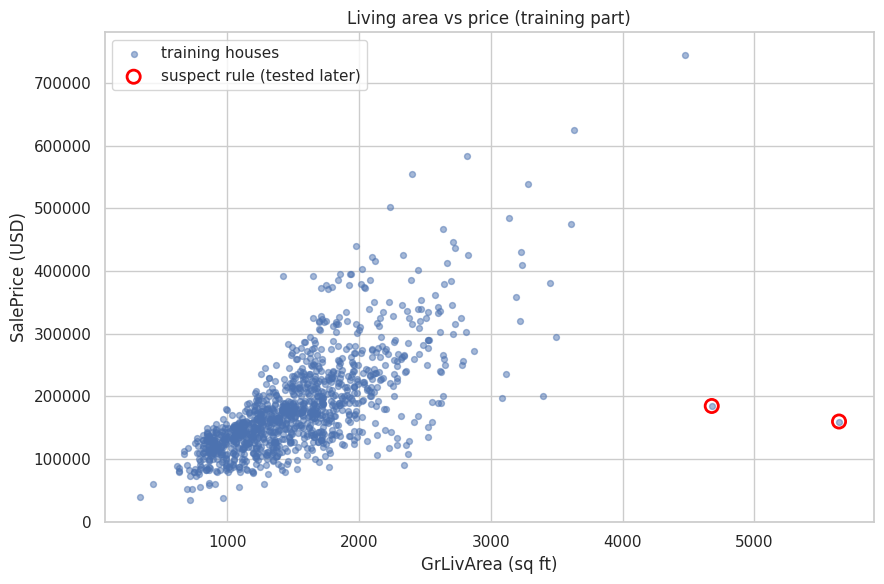

In [12]:
# Rule fixed in advance and applied to the TRAINING part only: very large living area but a low price.
suspect_mask = (X_train["GrLivArea"] > 4000) & (y_train < 300_000)
SUSPECT_IDX = X_train.index[suspect_mask]
print("Training houses with GrLivArea > 4000:", int((X_train["GrLivArea"] > 4000).sum()))
print("Of which priced < 300,000 (suspects):", len(SUSPECT_IDX))
display_cols = ["GrLivArea", "OverallQual", "SaleCondition", "Neighborhood"]
suspects = X_train.loc[SUSPECT_IDX, display_cols].assign(SalePrice=y_train.loc[SUSPECT_IDX], Id=train_raw.loc[SUSPECT_IDX, "Id"])
print(suspects.to_string())
print("\nOther very large houses in the training part (kept, because their price is consistent):")
big_ok = (X_train["GrLivArea"] > 4000) & ~suspect_mask
print(X_train.loc[big_ok, display_cols].assign(SalePrice=y_train[big_ok]).to_string())

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X_train["GrLivArea"], y_train, s=18, alpha=.5, label="training houses")
ax.scatter(X_train.loc[SUSPECT_IDX, "GrLivArea"], y_train.loc[SUSPECT_IDX], s=90, facecolors="none", edgecolors="red", linewidths=2, label="suspect rule (tested later)")
ax.set_xlabel("GrLivArea (sq ft)"); ax.set_ylabel("SalePrice (USD)"); ax.set_title("Living area vs price (training part)"); ax.legend()
plt.tight_layout(); save_fig("04_outlier_grlivarea.png"); plt.show()

**Finding.** A few very large houses sit far *below* the price trend (red circles), while other equally large houses are very expensive and consistent with the trend (kept). The red points are plausible data-quality / unusual-sale cases (their `SaleCondition` can be inspected above), but this is a **hypothesis**. Whether removing them helps is tested objectively in Section 14, on the same cross-validation folds and validation set as the baseline that keeps them.

## 10. Data Preprocessing (one reusable pipeline)
All preprocessing is a `ColumnTransformer` inside a `Pipeline`, so `fit` only ever sees training rows, and the identical transformation is applied to validation and test rows. Column groups are chosen by *name rules* (the lists from Section 6), never by looking at the target.

In [13]:
def add_features(df):
    # Optional feature engineering. Stateless: uses only the row's own values (no statistics learned from data).
    d = df.copy()
    bsmt = d["TotalBsmtSF"].fillna(0)
    d["TotalSF"]       = bsmt + d["1stFlrSF"] + d["2ndFlrSF"]
    d["TotalBath"]     = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"].fillna(0) + 0.5 * d["BsmtHalfBath"].fillna(0)
    d["HouseAge"]      = (d["YrSold"] - d["YearBuilt"]).clip(lower=0)
    d["RemodAge"]      = (d["YrSold"] - d["YearRemodAdd"]).clip(lower=0)
    d["HasGarage"]     = (d["GarageArea"].fillna(0) > 0).astype(int)
    d["HasBasement"]   = (bsmt > 0).astype(int)
    d["HasPool"]       = (d["PoolArea"] > 0).astype(int)
    d["HasFireplace"]  = (d["Fireplaces"] > 0).astype(int)
    return d

# Column selectors (callables, evaluated on the training data at fit time)
cols_zero_fill   = lambda df: [c for c in df.columns if c in ZERO_FILL_NUM]
cols_numeric     = lambda df: [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c not in ZERO_FILL_NUM]
cols_cat_absence = lambda df: [c for c in df.columns if c in ABSENCE_CAT]
cols_cat_unknown = lambda df: [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and c not in ABSENCE_CAT]

def make_preprocessor(scale):
    scaler = StandardScaler() if scale else "passthrough"
    onehot = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("zero_fill",   Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0)), ("scale", scaler)]), cols_zero_fill),
        ("numeric",     Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("scale", scaler)]), cols_numeric),
        ("cat_absence", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="None")), ("ohe", onehot())]), cols_cat_absence),
        ("cat_unknown", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", onehot())]), cols_cat_unknown),
    ], remainder="drop")

def build_model(estimator, log_target=True, engineer=False, scale=False):
    # features -> preprocessing -> estimator, wrapped so the target can be log-transformed and
    # predictions are automatically converted back to USD (expm1) before any metric is computed.
    pipe = Pipeline([
        ("features", FunctionTransformer(add_features if engineer else None, validate=False)),
        ("prep", make_preprocessor(scale)),
        ("model", estimator),
    ])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return TransformedTargetRegressor(regressor=pipe)   # identity transform: raw USD target

# Quick look at what the preprocessing produces (fitted on TRAINING rows only)
demo = build_model(Ridge(alpha=10), scale=True).fit(X_train, y_train)
prep_fitted = demo.regressor_.named_steps["prep"]
print("Model input: ", X_train.shape[1], "raw columns ->", len(prep_fitted.get_feature_names_out()), "model features after imputing + encoding + scaling")
for name, _, cols in prep_fitted.transformers_[:-1]:
    print(f"  {name:<12}: {len(cols)} columns")

Model input:  79 raw columns -> 316 model features after imputing + encoding + scaling
  zero_fill   : 9 columns
  numeric     : 26 columns
  cat_absence : 15 columns


**Design choices.**
- *Scaling* (`StandardScaler`) is applied only for the linear models, where feature scale affects regularisation. Tree models are invariant to scaling, so they get `passthrough`.
- *One-hot encoding* uses `handle_unknown="ignore"`, so a category that appears only in validation/test cannot crash the pipeline.
- The old `train_processed.csv` / `test_processed.csv` are **not used** (see Section 11 and the README): they were already scaled/encoded, so feeding them to this pipeline would transform the data twice.

## 11. Leakage and Validity Checks
Automated checks that make the evaluation process verifiable rather than assumed.

In [14]:
# 1. Target and Id are not features
assert TARGET not in X_train.columns and "Id" not in X_train.columns and TARGET not in X_test.columns
# 2. Train/validation rows are disjoint and together cover the labelled data
assert set(X_train.index).isdisjoint(X_val.index) and len(X_train) + len(X_val) == len(train_raw)
# 3. Test rows are only used at the very end (Section 21); they are unlabelled and not part of any split
assert len(X_test) == len(test_raw)
# 4. The scaler learned its statistics from TRAIN rows only
scaled_cols = cols_numeric(X_train)
learned_mean = prep_fitted.named_transformers_["numeric"].named_steps["scale"].mean_
train_mean = X_train[scaled_cols].median()  # (median-imputed first, so compare means below instead)
imputed_train = X_train[scaled_cols].fillna(X_train[scaled_cols].median())
imputed_all   = X_all[scaled_cols].fillna(X_train[scaled_cols].median())
j = scaled_cols.index("GrLivArea")
print(f"GrLivArea mean the scaler learned : {learned_mean[j]:.3f}")
print(f"  mean of training rows only      : {imputed_train['GrLivArea'].mean():.3f}   <- identical")
print(f"  mean of train+validation rows   : {imputed_all['GrLivArea'].mean():.3f}   <- would differ if validation had leaked in")
assert np.isclose(learned_mean[j], imputed_train["GrLivArea"].mean())
print("\nAll leakage checks passed.")

GrLivArea mean the scaler learned : 1527.402
  mean of training rows only      : 1527.402   <- identical
  mean of train+validation rows   : 1515.464   <- would differ if validation had leaked in

All leakage checks passed.


**What was wrong with the old `train_processed.csv`.** Its numeric columns have mean ≈ 0 and standard deviation = 1 *exactly* on the whole 1,460-row training file, which shows the scaler was fitted on **all** labelled rows. Any validation split made from that file would have already "seen" the validation rows' mean and spread (mild leakage), and it still contains `Id` as a feature and the target `SalePrice` beside the features. They are therefore **replaced** by the in-pipeline preprocessing above rather than corrected; no new processed CSV is generated because it would only reintroduce the leakage risk.

## 12. Reproducing the Original Notebook's Results
Before changing anything I re-run the **original** approach exactly as written (including its two flaws: `Id` used as a number and `MSSubClass` scaled as a number) and compare with the numbers that were printed in the original notebook.

In [15]:
# Original approach, reproduced faithfully (default NaN parsing, Id kept, MSSubClass numeric, 'None' fill)
legacy = pd.read_csv(DATA_DIR / "train.csv")
Xl, yl = legacy.drop("SalePrice", axis=1), legacy["SalePrice"]
Xl_tr, Xl_va, yl_tr, yl_va = train_test_split(Xl, yl, test_size=0.2, random_state=42)
assert (Xl_va.index == X_val.index).all(), "validation rows differ from the original split"
print("Validation rows identical to the original notebook's split: True")

num_l = Xl_tr.select_dtypes(include=["int64", "float64"]).columns
cat_l = Xl_tr.select_dtypes(exclude=["int64", "float64"]).columns
legacy_pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_l),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="None")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_l)])

def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

legacy_raw = Pipeline([("p", legacy_pre), ("m", LinearRegression())]).fit(Xl_tr, yl_tr)
legacy_log = Pipeline([("p", legacy_pre), ("m", LinearRegression())]).fit(Xl_tr, np.log1p(yl_tr))
legacy_pred_raw = legacy_raw.predict(Xl_va)
legacy_pred_log = np.expm1(legacy_log.predict(Xl_va))

ORIGINAL_REPORTED = {"LinearRegression (raw target)": (21126.16, 65340.38, 0.4434),
                     "LinearRegression (log1p target)": (15070.34, 22907.17, 0.9316)}
rows = []
for label, pred in [("LinearRegression (raw target)", legacy_pred_raw), ("LinearRegression (log1p target)", legacy_pred_log)]:
    s = scores(yl_va, pred); rep = ORIGINAL_REPORTED[label]
    rows.append({"model": label, "MAE": s["MAE"], "RMSE": s["RMSE"], "R2": s["R2"],
                 "orig. notebook MAE": rep[0], "orig. RMSE": rep[1], "orig. R2": rep[2]})
    assert abs(s["MAE"] - rep[0]) < 1 and abs(s["RMSE"] - rep[1]) < 1 and abs(s["R2"] - rep[2]) < 1e-3
legacy_table = pd.DataFrame(rows).set_index("model")
print("Re-computed vs. reported in the original notebook -> reproduced.\n")
legacy_table

Validation rows identical to the original notebook's split: True
Re-computed vs. reported in the original notebook -> reproduced.



,MAE,RMSE,R2,orig. notebook MAE,orig. RMSE,orig. R2
model,,,,,,
LinearRegression (raw target),"21,126.16","65,340.38",0.44,"21,126.16","65,340.38",0.44
LinearRegression (log1p target),"15,070.34","22,907.17",0.93,"15,070.34","22,907.17",0.93


In [16]:
# WHY is the raw-target R2 only ~0.44? Look at the single worst prediction.
err = (yl_va - legacy_pred_raw).abs()
worst_pos = int(np.argmax(err.values)); worst_idx = err.index[worst_pos]
print(f"Worst case: row Id {legacy.loc[worst_idx, 'Id']}: actual {yl_va[worst_idx]:,.0f}  vs predicted {legacy_pred_raw[worst_pos]:,.0f}")

mse_without = np.sqrt(np.mean(np.delete((yl_va.values - legacy_pred_raw) ** 2, worst_pos)))
print(f"RMSE with all 292 validation rows : {np.sqrt(np.mean((yl_va.values - legacy_pred_raw) ** 2)):,.0f}")
print(f"RMSE without that single row      : {mse_without:,.0f}")

fitted_pre = legacy_raw.named_steps["p"]
names = fitted_pre.get_feature_names_out()
row_t = fitted_pre.transform(Xl_va.loc[[worst_idx]])[0]
contrib = pd.Series(row_t * legacy_raw.named_steps["m"].coef_, index=names).sort_values()
print("\nLargest contributions to that prediction (USD):")
print(pd.concat([contrib.head(3), contrib.tail(2)]).round(0).to_string())

Worst case: row Id 1171: actual 171,000  vs predicted -839,463
RMSE with all 292 validation rows : 65,340
RMSE without that single row      : 27,845

Largest contributions to that prediction (USD):
cat__PoolQC_Gd          -1,630,342.00
cat__MiscFeature_None     -148,486.00
cat__RoofMatl_CompShg     -142,043.00
cat__Condition2_Norm        33,819.00
num__PoolArea            3,637,088.00


**Diagnosis (verified above).** The original numbers are reproduced exactly, so they were *real* — but the raw-target R² of 0.44 is driven by **one** validation house that the unregularised linear model predicted as a large *negative* price. The house has a pool, and only a couple of training houses have one: the model assigned huge, offsetting coefficients to the nearly-duplicate features `PoolArea` and `PoolQC_*`, which blow up when a new combination appears. This is classic multicollinearity + extrapolation in plain `LinearRegression`. Without that single row the RMSE drops massively.

So the jump from R² 0.44 to 0.93 in the original notebook was **not only** a benefit of the log transform: the log transform also made the pool-driven explosion impossible (predictions are `expm1` of a number, so they cannot go negative). Sections 13 and 16 separate these effects properly.

## 13. Baseline Models and the Log Target (new pipeline)
A single evaluation function is used for **every** model, so comparisons are fair: same 5-fold CV on the training part (`KFold(shuffle=True, random_state=42)`), same fitted-on-train / scored-on-validation rows, same metrics computed in USD.

In [17]:
KF = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FITTED, VAL_PRED = {}, {}
SCORE_CLEAN = False     # if True, the 2 suspect houses are also excluded from CV *scoring* (set in Section 14 after the decision)

def metric_dict(y_true, y_pred):
    return {"mae": mean_absolute_error(y_true, y_pred),
            "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "r2": r2_score(y_true, y_pred)}

def evaluate_model(name, model, drop_index=None):
    # 5-fold CV inside the TRAINING part, then fit on the whole training part and score on validation ONCE.
    # drop_index: training rows removed from the FITTING data only.
    # cv_rmse_all   = scored on every held-out row;  cv_rmse_clean = same folds, suspect rows not scored.
    # cv_rmse / cv_mae / cv_r2 follow the global SCORE_CLEAN policy (identical for every model compared).
    f_all, f_clean = [], []
    for tr_pos, te_pos in KF.split(X_train):
        tr_idx, te_idx = X_train.index[tr_pos], X_train.index[te_pos]
        if drop_index is not None:
            tr_idx = tr_idx[~tr_idx.isin(drop_index)]
        m = clone(model).fit(X_train.loc[tr_idx], y_train.loc[tr_idx])
        pred = pd.Series(m.predict(X_train.loc[te_idx]), index=te_idx)
        f_all.append(metric_dict(y_train.loc[te_idx], pred))
        keep = te_idx[~te_idx.isin(SUSPECT_IDX)]
        f_clean.append(metric_dict(y_train.loc[keep], pred.loc[keep]))
    cv_all, cv_clean = pd.DataFrame(f_all), pd.DataFrame(f_clean)
    cv = cv_clean if SCORE_CLEAN else cv_all

    fit_idx = X_train.index if drop_index is None else X_train.index[~X_train.index.isin(drop_index)]
    final = clone(model).fit(X_train.loc[fit_idx], y_train.loc[fit_idx])
    val_pred = final.predict(X_val)
    v = metric_dict(y_val, val_pred)
    FITTED[name], VAL_PRED[name] = final, val_pred
    return {"model": name,
            "cv_rmse": cv["rmse"].mean(), "cv_rmse_std": cv["rmse"].std(), "cv_mae": cv["mae"].mean(), "cv_r2": cv["r2"].mean(),
            "cv_rmse_all": cv_all["rmse"].mean(), "cv_rmse_clean": cv_clean["rmse"].mean(),
            "val_mae": v["mae"], "val_rmse": v["rmse"], "val_r2": v["r2"]}

def show(rows):
    return pd.DataFrame(rows).set_index("model")

t0 = time.time()
baseline_rows = [
    evaluate_model("Linear | raw target",   build_model(LinearRegression(), log_target=False, scale=True)),
    evaluate_model("Linear | log1p target", build_model(LinearRegression(), log_target=True,  scale=True)),
]
print(f"({time.time()-t0:.0f}s)")
show(baseline_rows)[["cv_rmse_all", "cv_rmse_clean", "val_mae", "val_rmse", "val_r2"]]

(1s)


,cv_rmse_all,cv_rmse_clean,val_mae,val_rmse,val_r2
model,,,,,
Linear | raw target,"40,851.54","34,483.93","21,506.60","70,478.11",0.35
Linear | log1p target,"54,225.75","27,876.46","15,187.18","23,401.13",0.93


**Reading the table** (all numbers come from the cell above).
- With the *cleaned* pipeline (no `Id`, `MSSubClass` as a category, explicit "absent" handling) the plain `LinearRegression` still **fails on the raw target**: validation RMSE ≈ 70.5k and R² ≈ 0.35. The cleaning alone did not remove the pool-type explosion diagnosed in Section 12.
- The `log1p` target fixes it: validation MAE ≈ 15.2k, RMSE ≈ 23.4k, R² ≈ 0.93. The new numbers differ a little from the original notebook (RMSE 22.9k) because the preprocessing is not identical (e.g. `Id` removed); they are not expected to match.
- **Why two CV columns?** `cv_rmse_all` scores every held-out house; `cv_rmse_clean` skips the two suspect houses from Section 9. For the log model they differ enormously (≈ 54k vs ≈ 28k), which means those two houses alone dominate the "all rows" CV error. Section 14 deals with this properly instead of ignoring it.

## 14. Outlier Treatment Experiment
Tests whether removing the suspect houses from the **fitting** data (never from the scoring data) changes performance. Compared against the baseline that keeps them, on identical folds. Rule fixed in advance: *adopt removal only if both Ridge and Random Forest improve on (a) validation RMSE and (b) cross-validated RMSE measured on the non-suspect rows (same folds; the suspects are not scored).*

In [18]:
def two_models(engineer):   # (feature engineering is tested AFTER this decision, in Section 15)
    return {"Ridge(10) log":       build_model(Ridge(alpha=10), True, engineer, scale=True),
            "RandomForest(150) log": build_model(RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1), True, engineer, scale=False)}

t0 = time.time()
out_rows = []
for name, mdl in two_models(False).items():
    out_rows.append(evaluate_model(f"{name} | keep all rows", mdl))
    out_rows.append(evaluate_model(f"{name} | drop {len(SUSPECT_IDX)} suspects from fitting", mdl, drop_index=SUSPECT_IDX))
out_table = show(out_rows)

improve = {}
for name in two_models(False):
    k, d = out_table.loc[f"{name} | keep all rows"], out_table.loc[f"{name} | drop {len(SUSPECT_IDX)} suspects from fitting"]
    improve[name] = bool(d["val_rmse"] < k["val_rmse"] and d["cv_rmse_clean"] < k["cv_rmse_clean"])
DROP_SUSPECTS = all(improve.values())
DROP_IDX = SUSPECT_IDX if DROP_SUSPECTS else None
SCORE_CLEAN = DROP_SUSPECTS      # from now on every model is CV-scored on the same rows: suspects excluded if they were dropped
print(f"({time.time()-t0:.0f}s)  Improvement per model: {improve}  ->  DROP_SUSPECTS = {DROP_SUSPECTS}  (CV scoring excludes suspects from now on: {SCORE_CLEAN})")
out_table[["cv_rmse_all", "cv_rmse_clean", "val_mae", "val_rmse", "val_r2"]]

(13s)  Improvement per model: {'Ridge(10) log': True, 'RandomForest(150) log': True}  ->  DROP_SUSPECTS = True  (CV scoring excludes suspects from now on: True)


,cv_rmse_all,cv_rmse_clean,val_mae,val_rmse,val_r2
model,,,,,
Ridge(10) log | keep all rows,"40,721.41","23,591.85","16,374.54","25,299.49",0.92
Ridge(10) log | drop 2 suspects from fitting,"54,080.05","19,947.94","14,834.41","22,282.34",0.94
RandomForest(150) log | keep all rows,"30,707.70","28,799.08","16,822.85","29,849.16",0.88
RandomForest(150) log | drop 2 suspects from fitting,"29,984.81","27,269.65","16,524.40","27,501.47",0.90


**Result.** For both models, dropping the two suspect houses (Ids 524 and 1299) **from the fitting data** improves validation RMSE (Ridge ≈ 25.3k → 22.3k, Random Forest ≈ 29.8k → 27.5k) and the cross-validated RMSE on the non-suspect rows (Ridge ≈ 23.6k → 19.9k, Random Forest ≈ 28.8k → 27.3k). The pre-declared rule is therefore satisfied and the two rows are excluded from fitting.

**Trade-offs and honesty notes.**
- Only **2 of 1,168** rows are affected. The 48 IQR-flagged expensive houses and the legitimate 745k house with 4,476 sq ft are **kept**.
- `cv_rmse_all` for Ridge gets *worse* (≈ 40.7k → 54.1k) when the suspects are dropped. That is expected, not a contradiction: when those two houses are held out and scored, a model that never saw an unusual 5,642 sq ft / 160k house predicts them badly. It means the final model is **not suited to houses of that unusual type**; it is not a free improvement everywhere.
- The suspects are a *hypothesis* about data quality (both are 'Partial' sales in 'Edwards' with a top quality rating and a very low price) — I cannot verify why they sold so cheaply from this file alone.
- The validation set contains no such house, so its improvement partly reflects the model no longer being distorted by them; the evidence base is small (2 points). From here on, all models are scored with the same rule (suspects excluded from CV scoring).

## 15. Feature Engineering - is it justified?
Eight simple, stateless features (`TotalSF`, `TotalBath`, `HouseAge`, `RemodAge`, `Has*` flags) are added. They use only a house's own columns (nothing learned from other rows and no target), so they cannot leak. To avoid over-engineering, a **pre-declared rule** decides: *keep them only if they lower the cross-validated RMSE for both a linear model (Ridge) and a tree model (Random Forest)*, using the outlier decision from Section 14 and the same scoring rows for both variants.

In [19]:
t0 = time.time()
fe_rows = []
for eng in (False, True):
    tag = "with FE" if eng else "no FE"
    fe_rows.append(evaluate_model(f"Ridge(10) log | {tag}", build_model(Ridge(alpha=10), True, eng, scale=True), drop_index=DROP_IDX))
    fe_rows.append(evaluate_model(f"RandomForest(150) log | {tag}",
                                  build_model(RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1), True, eng, scale=False), drop_index=DROP_IDX))
fe_table = show(fe_rows)
ridge_better = fe_table.loc["Ridge(10) log | with FE", "cv_rmse"] < fe_table.loc["Ridge(10) log | no FE", "cv_rmse"]
rf_better    = fe_table.loc["RandomForest(150) log | with FE", "cv_rmse"] < fe_table.loc["RandomForest(150) log | no FE", "cv_rmse"]
USE_FE = bool(ridge_better and rf_better)
print(f"({time.time()-t0:.0f}s)  Ridge improves with FE: {ridge_better} | Random Forest improves with FE: {rf_better}  ->  USE_FE = {USE_FE}")
fe_table[["cv_rmse", "cv_rmse_std", "cv_r2", "val_mae", "val_rmse", "val_r2"]]

(13s)  Ridge improves with FE: True | Random Forest improves with FE: True  ->  USE_FE = True


,cv_rmse,cv_rmse_std,cv_r2,val_mae,val_rmse,val_r2
model,,,,,,
Ridge(10) log | no FE,"19,947.94",837.82,0.93,"14,834.41","22,282.34",0.94
RandomForest(150) log | no FE,"27,269.65","1,708.61",0.87,"16,524.40","27,501.47",0.90
Ridge(10) log | with FE,"19,826.80",888.58,0.93,"14,869.24","22,369.37",0.93
RandomForest(150) log | with FE,"26,050.68","2,334.97",0.89,"16,256.33","27,608.03",0.90


**Result.** With the same scoring rows, the engineered features lower the CV RMSE for both models (Ridge ≈ 19,948 → 19,827, i.e. −0.6 %; Random Forest ≈ 27,270 → 26,051, i.e. −4.5 %), so the pre-declared rule keeps them (`USE_FE = True`).

**Be realistic about the size of the effect.** The Ridge gain is tiny compared with the fold-to-fold variation (CV std ≈ 0.9k–2.3k), and on the validation set both models are marginally *worse* with the new features (Ridge ≈ 22,282 → 22,369; Random Forest ≈ 27,501 → 27,608). The rule says "keep", but the honest conclusion is that feature engineering gives **at most a small benefit** here; the model would be almost as good without it. Dropping it would also have been defensible.

## 16. Model Training and Comparison
Four model families, each with the raw and the `log1p` target, using the feature-engineering and outlier decisions made above. Default (untuned) hyperparameters except a fixed, sensible Ridge `alpha`. Linear models get scaled inputs; tree models do not need scaling.

In [20]:
print(f"Settings carried forward -> feature engineering: {USE_FE} | drop suspects: {DROP_SUSPECTS} | CV scoring excludes suspects: {SCORE_CLEAN}")
def rf(): return RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1)
def hgb(): return HistGradientBoostingRegressor(random_state=SEED)

specs = [("Linear",            LinearRegression, True), ("Ridge(10)",         lambda: Ridge(alpha=10), True),
         ("RandomForest(150)", rf, False),                ("HistGradBoost",     hgb, False)]
t0 = time.time()
compare_rows = []
for fam, factory, scale in specs:
    for log_t in (False, True):
        label = f"{fam} | {'log1p' if log_t else 'raw'} target"
        compare_rows.append(evaluate_model(label, build_model(factory(), log_t, USE_FE, scale), drop_index=DROP_IDX))
print(f"({time.time()-t0:.0f}s)")
compare_table = show(compare_rows).sort_values("cv_rmse")
compare_table[["cv_rmse", "cv_rmse_std", "cv_r2", "val_mae", "val_rmse", "val_r2"]]

Settings carried forward -> feature engineering: True | drop suspects: True | CV scoring excludes suspects: True
(29s)


,cv_rmse,cv_rmse_std,cv_r2,val_mae,val_rmse,val_r2
model,,,,,,
Ridge(10) | log1p target,"19,826.80",888.58,0.93,"14,869.24","22,369.37",0.93
Ridge(10) | raw target,"23,754.30","2,023.32",0.91,"17,713.14","27,826.72",0.90
HistGradBoost | log1p target,"24,498.57","3,146.86",0.90,"15,526.09","26,556.50",0.91
HistGradBoost | raw target,"25,342.38","3,379.07",0.89,"15,840.62","27,019.17",0.90
RandomForest(150) | raw target,"25,360.81","2,281.53",0.89,"16,932.68","28,728.13",0.89
RandomForest(150) | log1p target,"26,050.68","2,334.97",0.89,"16,256.33","27,608.03",0.90
Linear | log1p target,"26,597.66","6,359.94",0.87,"15,356.73","23,309.72",0.93
Linear | raw target,"32,646.03","12,218.61",0.79,"21,700.48","71,263.55",0.34


**What the table shows** (sorted by CV RMSE; lower is better).
- **Log target:** it is essential for plain linear regression (validation RMSE ≈ 71.3k → 23.3k) and helps Ridge (CV RMSE ≈ 23.8k → 19.8k). For gradient boosting the gain is small (≈ 25.3k → 24.5k) and for Random Forest it is mixed (CV slightly worse, validation slightly better), which is what one expects since trees do not suffer from skewed targets in the same way.
- **Regularisation:** Ridge vs. plain Linear on the log target cuts the CV RMSE from ≈ 26.6k to ≈ 19.8k and the fold-to-fold std from ≈ 6.4k to ≈ 0.9k — a much more stable model.
- **Trees vs. Ridge:** the tree ensembles did **not** beat the regularised linear model here. With only ~1.2k training rows and many near-linear relationships (in log-price), a simple regularised model is competitive; this should not be generalised to other datasets.

## 17. Hyperparameter Tuning
Tuning is limited and purposeful: only the three promising families on the `log1p` target, with a small search (8-10 candidates for the tree models, a 1-D grid for Ridge), scored by 5-fold CV RMSE on the **training part only**. The validation set is not used for tuning.

In [21]:
fit_idx = X_train.index if DROP_IDX is None else X_train.index[~X_train.index.isin(DROP_IDX)]
X_tune, y_tune = X_train.loc[fit_idx], y_train.loc[fit_idx]
scoring = "neg_root_mean_squared_error"          # computed on the USD scale (target is inverse-transformed)

# Tuning folds = EXACTLY the folds used by evaluate_model: same held-out rows, suspects removed from fitting
# (and from scoring when SCORE_CLEAN is True), so tuned and untuned models are compared on identical rows.
pos = {idx: i for i, idx in enumerate(X_tune.index)}
cv_splits = []
for tr_pos, te_pos in KF.split(X_train):
    tr = [pos[i] for i in X_train.index[tr_pos] if i in pos]
    te = [pos[i] for i in X_train.index[te_pos] if i in pos and not (SCORE_CLEAN and i in SUSPECT_IDX)]
    cv_splits.append((np.array(tr), np.array(te)))

searches = {
    "Ridge": GridSearchCV(build_model(Ridge(), True, USE_FE, True),
                          {"regressor__model__alpha": [0.1, 0.3, 1, 3, 10, 30, 100, 300]}, cv=cv_splits, scoring=scoring),
    "RandomForest": RandomizedSearchCV(build_model(RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1), True, USE_FE, False),
                          {"regressor__model__max_depth": [None, 12, 20], "regressor__model__min_samples_leaf": [1, 2, 4],
                           "regressor__model__max_features": [0.2, 0.33, 0.5]},
                          n_iter=8, cv=cv_splits, scoring=scoring, random_state=SEED),
    "HistGradBoost": RandomizedSearchCV(build_model(HistGradientBoostingRegressor(random_state=SEED), True, USE_FE, False),
                          {"regressor__model__learning_rate": [0.03, 0.05, 0.1], "regressor__model__max_iter": [200, 400],
                           "regressor__model__max_leaf_nodes": [8, 15, 31], "regressor__model__min_samples_leaf": [10, 20, 40],
                           "regressor__model__l2_regularization": [0, 1, 10]},
                          n_iter=10, cv=cv_splits, scoring=scoring, random_state=SEED),
}
best_params = {}
for name, s in searches.items():
    t0 = time.time(); s.fit(X_tune, y_tune)
    best_params[name] = {k.replace("regressor__model__", ""): v for k, v in s.best_params_.items()}
    print(f"{name:<14} best CV RMSE = {-s.best_score_:>9,.0f}  ({time.time()-t0:.0f}s)  params: {best_params[name]}")

Ridge          best CV RMSE =    19,827  (2s)  params: {'alpha': 10}
RandomForest   best CV RMSE =    26,079  (33s)  params: {'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 12}
HistGradBoost  best CV RMSE =    23,264  (80s)  params: {'min_samples_leaf': 10, 'max_leaf_nodes': 8, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 10}


In [22]:
# Re-evaluate the tuned models with the SAME evaluation function (same folds, same validation rows)
tuned_rows = [evaluate_model(f"{n} (tuned) | log1p target", s.best_estimator_, drop_index=DROP_IDX) for n, s in searches.items()]
tuned_table = show(tuned_rows)
print("Check - CV RMSE found by the search vs recomputed by evaluate_model:")
for (n, s), r in zip(searches.items(), tuned_rows):
    print(f"  {n:<14} search {-s.best_score_:>10,.0f}  |  evaluate_model {r['cv_rmse']:>10,.0f}")
tuned_table[["cv_rmse", "cv_rmse_std", "cv_r2", "val_mae", "val_rmse", "val_r2"]]

Check - CV RMSE found by the search vs recomputed by evaluate_model:
  Ridge          search     19,827  |  evaluate_model     19,827
  RandomForest   search     26,079  |  evaluate_model     26,079
  HistGradBoost  search     23,264  |  evaluate_model     23,264


,cv_rmse,cv_rmse_std,cv_r2,val_mae,val_rmse,val_r2
model,,,,,,
Ridge (tuned) | log1p target,"19,826.80",888.58,0.93,"14,869.24","22,369.37",0.93
RandomForest (tuned) | log1p target,"26,079.11","2,452.00",0.89,"16,555.26","28,193.34",0.90
HistGradBoost (tuned) | log1p target,"23,264.47","2,769.70",0.91,"15,369.17","26,957.53",0.91


**Result.** The search confirmed `alpha = 10` for Ridge (an interior value of the grid, so the grid was wide enough) — the tuned Ridge is therefore identical to the untuned one, and the two table rows have identical numbers. Tuning gave the boosting model a CV improvement (≈ 24.5k → 23.3k) but its validation RMSE did not improve (≈ 26.6k → 27.0k), and it gave Random Forest no CV benefit (≈ 26.05k → 26.08k). Tuning gains were small relative to the CV standard deviations (up to ≈ 2.8k), so I did not expand the search. The printed check shows the search's CV score equals the one recomputed by `evaluate_model`, confirming both use identical folds and scoring rows.

## 18. Final Model Selection
Selection rule (declared before looking at the result): **lowest cross-validated RMSE on the training part** among all evaluated models (all scored on identical rows). The validation scores are then used only as an independent confirmation, not to choose.

Selected model (lowest CV RMSE): Ridge(10) | log1p target
Rank by validation RMSE of the selected model: 1 of 11


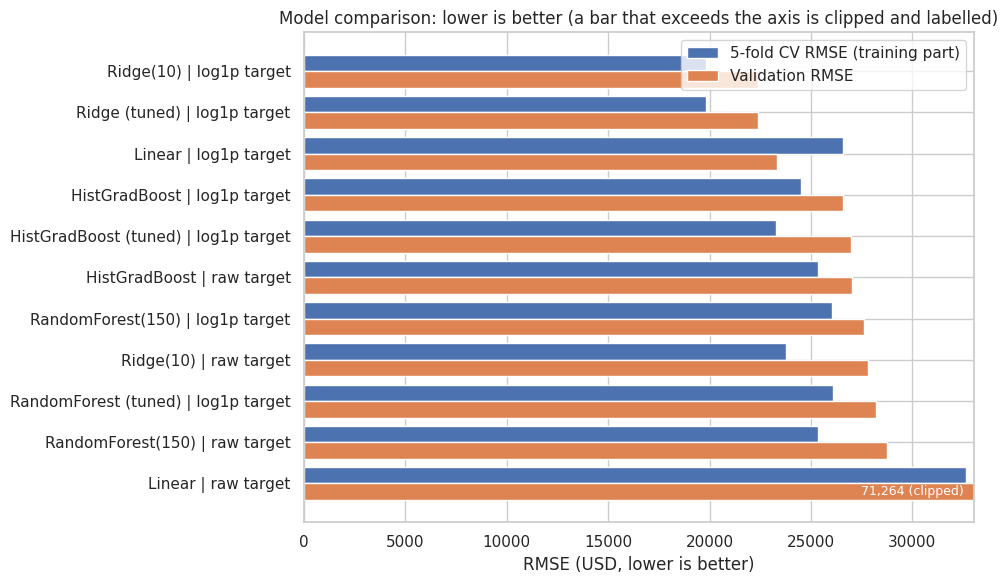

,CV RMSE,CV RMSE std,CV MAE,CV R2,Val MAE,Val RMSE,Val R2
model,,,,,,,
Ridge(10) | log1p target,"19,826.80",888.58,"13,323.70",0.93,"14,869.24","22,369.37",0.93
Ridge (tuned) | log1p target,"19,826.80",888.58,"13,323.70",0.93,"14,869.24","22,369.37",0.93
HistGradBoost (tuned) | log1p target,"23,264.47","2,769.70","14,615.11",0.91,"15,369.17","26,957.53",0.91
Ridge(10) | raw target,"23,754.30","2,023.32","15,775.54",0.91,"17,713.14","27,826.72",0.90
HistGradBoost | log1p target,"24,498.57","3,146.86","15,595.22",0.90,"15,526.09","26,556.50",0.91
HistGradBoost | raw target,"25,342.38","3,379.07","15,840.47",0.89,"15,840.62","27,019.17",0.90
RandomForest(150) | raw target,"25,360.81","2,281.53","16,409.61",0.89,"16,932.68","28,728.13",0.89
RandomForest(150) | log1p target,"26,050.68","2,334.97","16,492.89",0.89,"16,256.33","27,608.03",0.90
RandomForest (tuned) | log1p target,"26,079.11","2,452.00","16,487.33",0.89,"16,555.26","28,193.34",0.90


In [23]:
all_table = pd.concat([compare_table, tuned_table]).sort_values("cv_rmse")
BEST_NAME = all_table.index[0]
print("Selected model (lowest CV RMSE):", BEST_NAME)
print("Rank by validation RMSE of the selected model:", int(all_table["val_rmse"].rank().loc[BEST_NAME]), "of", len(all_table))

final_table = all_table[["cv_rmse", "cv_rmse_std", "cv_mae", "cv_r2", "val_mae", "val_rmse", "val_r2"]].copy()
final_table.columns = ["CV RMSE", "CV RMSE std", "CV MAE", "CV R2", "Val MAE", "Val RMSE", "Val R2"]
final_table.to_csv(OUT_DIR / "model_comparison.csv", index_label="model")

plot_df = all_table.sort_values("val_rmse", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(plot_df))
ax.barh(y_pos + 0.2, plot_df["cv_rmse"], height=0.4, label="5-fold CV RMSE (training part)", color="#4C72B0")
ax.barh(y_pos - 0.2, plot_df["val_rmse"], height=0.4, label="Validation RMSE", color="#DD8452")
ax.set_yticks(y_pos); ax.set_yticklabels(plot_df.index); ax.set_xlabel("RMSE (USD, lower is better)")
ax.set_xlim(0, plot_df[["cv_rmse", "val_rmse"]].quantile(0.9).max() * 1.15)
xmax = plot_df[["cv_rmse", "val_rmse"]].quantile(0.9).max() * 1.15
for yy, v in zip(y_pos - 0.2, plot_df["val_rmse"]):
    if v > xmax: ax.text(xmax * 0.985, yy, f"{v:,.0f} (clipped)", ha="right", va="center", color="white", fontsize=9)
ax.set_title("Model comparison: lower is better (a bar that exceeds the axis is clipped and labelled)"); ax.legend(loc="upper right")
plt.tight_layout(); save_fig("05_model_comparison.png"); plt.show()
final_table

**Selected model: Ridge regression (α = 10) on a `log1p` target, with the engineered features, fitted without the 2 suspect rows.**

| Evidence | Value |
|---|---|
| CV RMSE (training part, 5 folds) | ≈ 19.8k USD (std ≈ 0.9k) |
| Validation MAE / RMSE / R² | ≈ 14.9k USD / ≈ 22.4k USD / ≈ 0.935 |
| Rank by CV RMSE / by validation RMSE | 1st / 1st of the 11 rows |

It was chosen by the pre-declared CV rule and the validation set agrees, which is reassuring. Practical advantages: fast, stable across folds, easy to explain, almost no tuning. **Caveats:** the differences between Ridge and the plain log-target Linear model on validation (≈ 22.4k vs ≈ 23.3k RMSE) are small, and the validation set (292 houses) has been used to report 11 models and in the outlier decision, so its numbers are slightly optimistic. A linear model also **extrapolates** outside the training range (see Section 21).

## 19. Model Evaluation and Error Analysis (selected model, validation set)

Ridge(10) | log1p target
  MAE  = 14,869 USD   RMSE = 22,369 USD   R2 = 0.9348
  Median absolute % error = 6.4%   |   mean bias (actual - predicted) = -144 USD


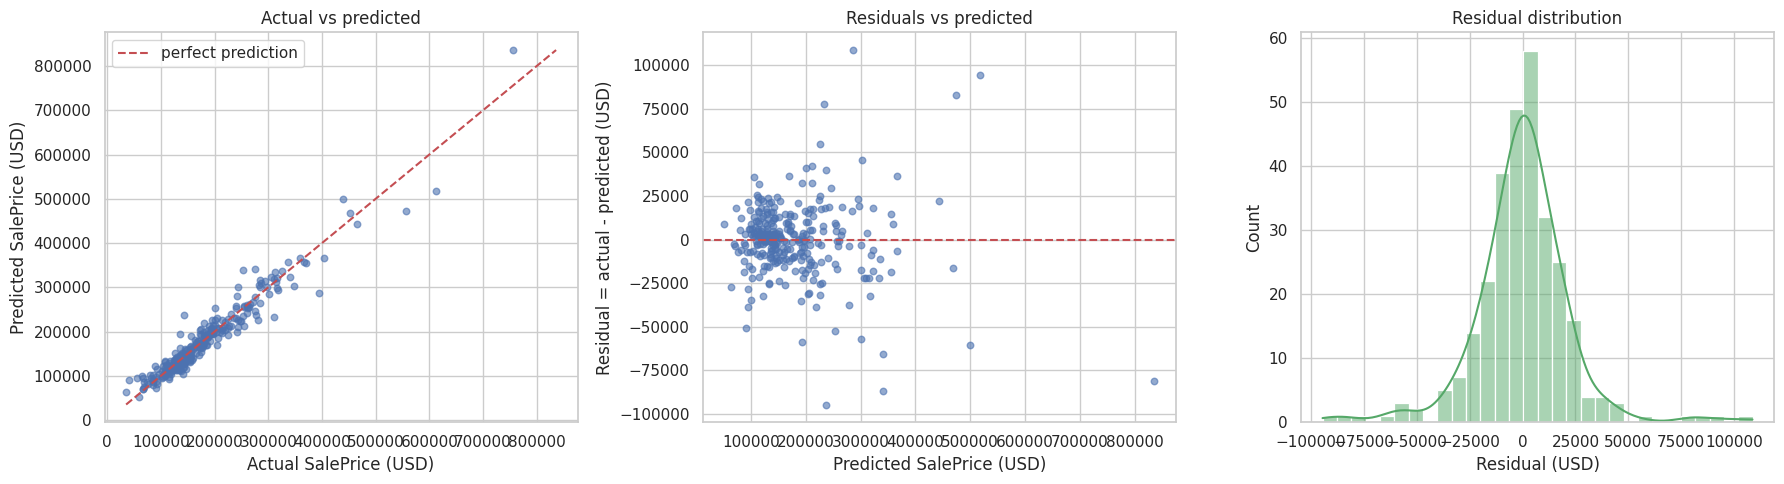

In [24]:
best_val_pred = pd.Series(VAL_PRED[BEST_NAME], index=X_val.index)
resid = y_val - best_val_pred
pct_err = resid / y_val * 100
m = metric_dict(y_val, best_val_pred)
print(f"{BEST_NAME}\n  MAE  = {m['mae']:,.0f} USD   RMSE = {m['rmse']:,.0f} USD   R2 = {m['r2']:.4f}")
print(f"  Median absolute % error = {pct_err.abs().median():.1f}%   |   mean bias (actual - predicted) = {resid.mean():,.0f} USD")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_val, best_val_pred, alpha=.6, s=22)
lims = [min(y_val.min(), best_val_pred.min()), max(y_val.max(), best_val_pred.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction"); axes[0].legend()
axes[0].set_xlabel("Actual SalePrice (USD)"); axes[0].set_ylabel("Predicted SalePrice (USD)"); axes[0].set_title("Actual vs predicted")
axes[1].scatter(best_val_pred, resid, alpha=.6, s=22); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted SalePrice (USD)"); axes[1].set_ylabel("Residual = actual - predicted (USD)"); axes[1].set_title("Residuals vs predicted")
sns.histplot(resid, bins=30, kde=True, ax=axes[2], color="#55A868")
axes[2].set_xlabel("Residual (USD)"); axes[2].set_title("Residual distribution")
plt.tight_layout(); save_fig("06_actual_vs_predicted_residuals.png"); plt.show()

**Findings.** Predictions follow the diagonal closely. The residuals are roughly bell-shaped and centred near zero (mean ≈ −144 USD), so the model is not systematically too high or too low overall. The spread of residuals grows with the price level (expected in USD terms), and a handful of houses have errors around ±100k. The most expensive house (≈ 755k) is over-predicted by roughly 80k. **Practical meaning:** typical errors are modest, but a single prediction can still be off by tens of thousands of dollars, especially for expensive houses.

Error by price quartile:
                    n  MAE (USD)  median |% error|  bias (USD)
SalePrice                                                     
Q1 cheapest        75  10,573.50              7.50   -4,843.60
Q2                 71  11,426.30              5.30    1,470.40
Q3                 73  12,773.30              5.90   -3,028.20
Q4 most expensive  73  24,727.30              6.10    5,998.60

Error by OverallQual:
              n  MAE (USD)  median |% error|
OverallQual                                 
2             2  18,034.60             46.00
3             4  12,123.70             16.10
4            28  14,086.30              9.50
5            89  11,248.30              5.80
6            63  10,962.60              6.40
7            61  16,272.50              5.80
8            33  22,698.90              6.10
9-10         12  35,783.90              5.20

Five largest errors:
  Id Neighborhood  OverallQual  GrLivArea  actual  predicted      error
 775      NridgHt            8

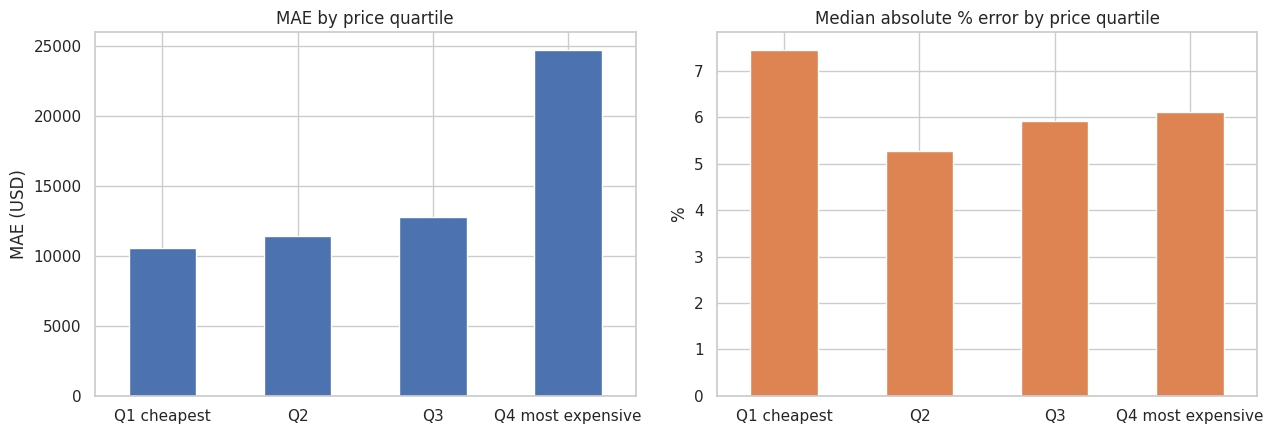

In [25]:
# Do errors depend on the price level and on quality? (bins are created from validation prices for ANALYSIS only)
band = pd.qcut(y_val, 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])
by_price = pd.DataFrame({"n": resid.groupby(band, observed=True).size(),
                         "MAE (USD)": resid.abs().groupby(band, observed=True).mean(),
                         "median |% error|": pct_err.abs().groupby(band, observed=True).median(),
                         "bias (USD)": resid.groupby(band, observed=True).mean()})
print("Error by price quartile:"); display_price = by_price; print(display_price.round(1).to_string())

qual = X_val["OverallQual"].clip(upper=9).astype(int).astype(str).replace({"9": "9-10"})
by_quality = pd.DataFrame({"n": resid.groupby(qual).size(), "MAE (USD)": resid.abs().groupby(qual).mean(),
                           "median |% error|": pct_err.abs().groupby(qual).median()})
print("\nError by OverallQual:"); print(by_quality.round(1).to_string())

worst = resid.abs().sort_values(ascending=False).head(5).index
worst_tbl = pd.DataFrame({"Id": train_raw.loc[worst, "Id"], "Neighborhood": X_val.loc[worst, "Neighborhood"],
                          "OverallQual": X_val.loc[worst, "OverallQual"], "GrLivArea": X_val.loc[worst, "GrLivArea"],
                          "actual": y_val[worst], "predicted": best_val_pred[worst].round(0), "error": resid[worst].round(0)})
print("\nFive largest errors:"); print(worst_tbl.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
by_price["MAE (USD)"].plot.bar(ax=axes[0], color="#4C72B0", rot=0); axes[0].set_title("MAE by price quartile"); axes[0].set_ylabel("MAE (USD)"); axes[0].set_xlabel("")
by_price["median |% error|"].plot.bar(ax=axes[1], color="#DD8452", rot=0); axes[1].set_title("Median absolute % error by price quartile"); axes[1].set_ylabel("%"); axes[1].set_xlabel("")
plt.tight_layout(); save_fig("07_error_by_price_band.png"); plt.show()

**Findings.**
- In dollars the error roughly doubles in the most expensive quartile (MAE ≈ 24.7k vs ≈ 10.6k–12.8k), but in **relative** terms it is similar across quartiles (median absolute error ≈ 5–7.5 %). This is consistent with the log target, which makes the model optimise percentage rather than dollar errors.
- Small systematic tendencies exist: the cheapest quartile is on average over-predicted by ≈ 4.8k and the most expensive under-predicted by ≈ 6.0k (bias = actual − predicted). Regularised models tend to pull extreme values toward the middle.
- By quality, the worst *relative* errors are in the lowest-quality groups, but those groups have very few houses (n = 2 and 4), so they are unreliable. The top-quality group (9–10, n = 12) has a large dollar error (≈ 35.8k) but a median error of only ≈ 5 %.
- Four of the five largest errors are in the high-end neighbourhoods `NridgHt` and `StoneBr` (the fifth is a mid-quality `ClearCr` house over-predicted by ≈ 95k), where there are fewer comparable sales.

**Practical meaning:** a good summary for a client is "typically within about 6 % of the price, with larger dollar errors for expensive homes", not a fixed ± dollar figure.

## 20. Feature Importance (Permutation Importance)
Permutation importance shuffles one **original input column** at a time on the validation set and measures how much the (USD-scale) RMSE gets worse. It works on the whole pipeline, so one-hot columns are not split into fragments. It describes what *this fitted model relies on*; it is not evidence of what *causes* prices.

(11s)  Top 15 features by RMSE increase when shuffled (USD):


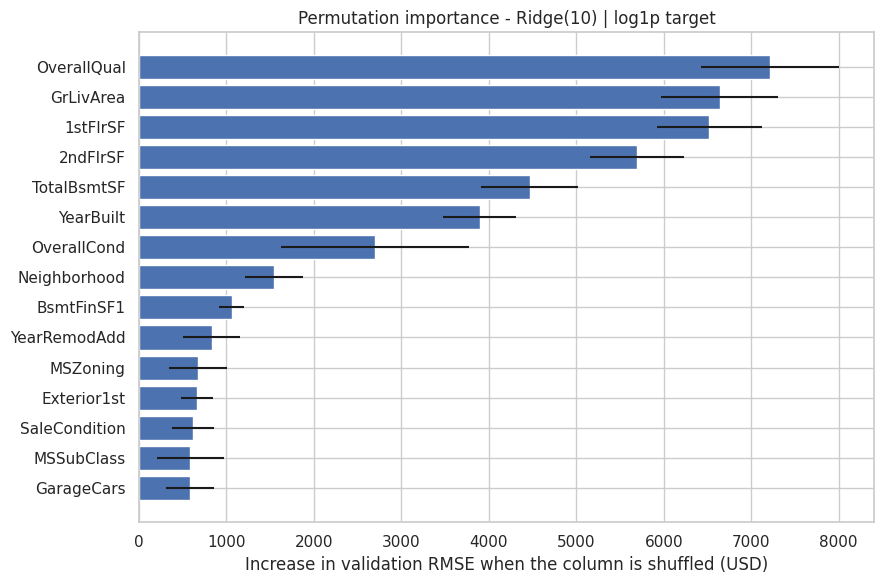

'     feature  rmse_increase      std\n OverallQual       7,213.00   791.00\n   GrLivArea       6,639.00   673.00\n    1stFlrSF       6,520.00   600.00\n    2ndFlrSF       5,695.00   537.00\n TotalBsmtSF       4,466.00   550.00\n   YearBuilt       3,895.00   418.00\n OverallCond       2,698.00 1,079.00\nNeighborhood       1,541.00   332.00\n  BsmtFinSF1       1,060.00   144.00\nYearRemodAdd         835.00   326.00'

In [26]:
t0 = time.time()
perm = permutation_importance(FITTED[BEST_NAME], X_val, y_val, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": X_val.columns, "rmse_increase": perm.importances_mean, "std": perm.importances_std}).sort_values("rmse_increase", ascending=False)
print(f"({time.time()-t0:.0f}s)  Top 15 features by RMSE increase when shuffled (USD):")
top15 = imp.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top15["feature"], top15["rmse_increase"], xerr=top15["std"], color="#4C72B0")
plt.xlabel("Increase in validation RMSE when the column is shuffled (USD)"); plt.title(f"Permutation importance - {BEST_NAME}")
plt.tight_layout(); save_fig("08_permutation_importance.png"); plt.show()
imp.head(10).round(0).to_string(index=False)

**Findings.** Shuffling `OverallQual` hurts the model most (RMSE up by ≈ 7.2k USD), followed by `GrLivArea`, `1stFlrSF`, `2ndFlrSF`, `TotalBsmtSF` and `YearBuilt`. The model relies mainly on build quality, living area and age.

**What this does and does not show.**
- It shows which inputs *this fitted model* depends on for *these* validation houses (292 rows, so the bars have uncertainty — see the error bars).
- `GrLivArea`, `1stFlrSF` and `2ndFlrSF` are almost arithmetically related; when features are strongly correlated, shuffling one is partly compensated by the others, so individual importances are **understated and shared** among them. Neighbourhood probably looks modest partly because its effect is also captured by quality and year built.
- It does **not** show that quality or size *cause* higher prices, nor what would happen if a specific house were renovated.

## 21. Predictions on the Unseen (Unlabelled) Test Data
The selected model configuration is refitted on **all 1,460 labelled houses** (train + validation rows; the same suspect-removal decision is applied), then used to predict `test.csv`. These predictions **cannot be scored** because `test.csv` has no `SalePrice`; the validation metrics above are the only performance evidence.

In [27]:
final_model = clone(FITTED[BEST_NAME])
full_idx = X_all.index if not DROP_SUSPECTS else X_all.index[~X_all.index.isin(SUSPECT_IDX)]
final_model.fit(X_all.loc[full_idx], y_all.loc[full_idx])
test_pred = final_model.predict(X_test)

# Sanity checks (these are NOT performance metrics)
assert X_test.columns.equals(X_all.columns) and len(test_pred) == len(test_raw)
assert np.isfinite(test_pred).all() and (test_pred > 0).all()
unseen = {c: int((~X_test[c].isin(X_all[c].unique()) & X_test[c].notna()).sum()) for c in X_test.select_dtypes(exclude="number").columns}
print("Test categories never seen in training (rows):", {k: v for k, v in unseen.items() if v} or "none")
print(f"Rows used to fit the final model: {len(full_idx)}")
print("Predicted price summary (test) vs actual price summary (train):")
print(pd.DataFrame({"test predictions": pd.Series(test_pred).describe(), "train actual": y_all.describe()}).round(0).to_string())

submission = pd.DataFrame({"Id": test_ids.values, "SalePrice": np.round(test_pred, 2)})
assert submission["Id"].tolist() == test_raw["Id"].tolist()          # row order and ids preserved
submission.to_csv(OUT_DIR / "test_predictions.csv", index=False)

val_out = pd.DataFrame({"Id": train_raw.loc[X_val.index, "Id"].values, "actual_SalePrice": y_val.values,
                        "predicted_SalePrice": best_val_pred.round(2).values, "error": resid.round(2).values})
val_out.to_csv(OUT_DIR / "validation_predictions.csv", index=False)

summary = {"selected_model": BEST_NAME, "use_feature_engineering": USE_FE, "drop_suspect_rows": DROP_SUSPECTS,
           "n_suspect_rows": int(len(SUSPECT_IDX)), "best_params": best_params, "seed": SEED,
           "validation": {k: float(v) for k, v in metric_dict(y_val, best_val_pred).items()},
           "cv_rmse_mean": float(all_table.loc[BEST_NAME, "cv_rmse"]), "cv_rmse_std": float(all_table.loc[BEST_NAME, "cv_rmse_std"]),
           "library_versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}}
json.dump(summary, open(OUT_DIR / "metrics_summary.json", "w"), indent=2)
print("\nSaved:", sorted(p.name for p in OUT_DIR.iterdir()))
submission.head()

Test categories never seen in training (rows): {'MSSubClass': 1}
Rows used to fit the final model: 1458
Predicted price summary (test) vs actual price summary (train):
       test predictions  train actual
count          1,459.00      1,460.00
mean         179,401.00    180,921.00
std           87,825.00     79,443.00
min           45,038.00     34,900.00
25%          125,860.00    129,975.00
50%          156,576.00    163,000.00
75%          210,471.00    214,000.00
max        1,693,230.00    755,000.00

Saved: ['metrics_summary.json', 'model_comparison.csv', 'prediction_warnings.csv', 'test_predictions.csv', 'validation_predictions.csv']


,Id,SalePrice
0,1461,"116,745.67"
1,1462,"152,704.14"
2,1463,"179,230.24"
3,1464,"199,071.95"
4,1465,"192,770.69"


In [28]:
# Extrapolation check: a linear model can produce unreliable values for houses outside the range it was trained on.
# 1) which test houses lie outside the training range on the model's most important numeric inputs?
# 2) what does a model that cannot extrapolate (tuned gradient boosting) predict for them?
fit_X = X_all.loc[full_idx]
key_numeric = [f for f in imp["feature"].head(10) if pd.api.types.is_numeric_dtype(X_all[f])]
outside = (X_test[key_numeric] < fit_X[key_numeric].min()) | (X_test[key_numeric] > fit_X[key_numeric].max())
too_high_low = (test_pred > y_all.max()) | (test_pred < y_all.min())
flag = outside.any(axis=1).values | too_high_low

cross_model = clone(FITTED["HistGradBoost (tuned) | log1p target"]).fit(X_all.loc[full_idx], y_all.loc[full_idx])
cross_pred = cross_model.predict(X_test)
agree = np.abs(np.log(test_pred) - np.log(cross_pred))
print(f"Key numeric inputs checked: {key_numeric}")
print(f"Test houses flagged (outside training range on a key input, or predicted outside the training price range): {int(flag.sum())} of {len(X_test)}")
print(f"Ridge vs boosting on all test houses: median |log difference| = {np.median(agree):.3f} (~{np.median(agree)*100:.1f}%), "
      f"correlation of log-predictions = {np.corrcoef(np.log(test_pred), np.log(cross_pred))[0, 1]:.3f}")

warn = pd.DataFrame({"Id": test_ids.values, "predicted_SalePrice": np.round(test_pred, 2),
                     "cross_check_boosting_prediction": np.round(cross_pred, 2),
                     "inputs_outside_training_range": [", ".join(key_numeric[j] for j in np.where(r)[0]) for r in outside.values]})[flag]
warn["ratio_ridge_to_boosting"] = (warn["predicted_SalePrice"] / warn["cross_check_boosting_prediction"]).round(2)
warn = warn.sort_values("ratio_ridge_to_boosting", ascending=False)
warn.to_csv(OUT_DIR / "prediction_warnings.csv", index=False)
print("\nFlagged houses where the two models disagree most:")
print(warn.head(6).to_string(index=False))

Key numeric inputs checked: ['OverallQual', 'GrLivArea', '1stFlrSF', '2ndFlrSF', 'TotalBsmtSF', 'YearBuilt', 'OverallCond', 'BsmtFinSF1', 'YearRemodAdd']
Test houses flagged (outside training range on a key input, or predicted outside the training price range): 4 of 1459
Ridge vs boosting on all test houses: median |log difference| = 0.039 (~3.9%), correlation of log-predictions = 0.984

Flagged houses where the two models disagree most:
  Id  predicted_SalePrice  cross_check_boosting_prediction                inputs_outside_training_range  ratio_ridge_to_boosting
2550         1,693,229.73                       616,095.57 GrLivArea, 1stFlrSF, TotalBsmtSF, BsmtFinSF1                     2.75
2189           321,964.60                       256,928.34                                     1stFlrSF                     1.25
1664           560,374.48                       528,223.34                                   BsmtFinSF1                     1.06
1975           398,610.31                 

**Findings.**
- On the other 1,455 houses the two very different models agree closely (median difference ≈ 4 %, correlation of log-predictions ≈ 0.98).
- Test house **Id 2550** has a living area of 5,095 sq ft (the largest training house kept for fitting is 4,476), with the same pattern as the two suspect training houses. Ridge predicts ≈ 1.69 million USD, gradient boosting ≈ 0.62 million — a factor of 2.75. A linear model keeps extending its trend beyond the data it saw; **the Ridge prediction for this house should not be trusted**. Neither value can be verified because the test file has no `SalePrice`.
- I did **not** silently change that prediction: `outputs/test_predictions.csv` contains the model's raw output, and `outputs/prediction_warnings.csv` lists the 4 flagged houses with the cross-check values. In a real project one would cap such predictions, use a bounded model for them, or refer them for manual review.

## 22. Final Findings and Limitations

### Main findings
1. **The original results are real but misleading.** Re-running the original code gives exactly the printed numbers (R² 0.4434 raw, 0.9316 log). The 0.44 was caused by one validation house predicted at about −839k USD by an unregularised model (RMSE 65,340 → 27,845 without that one row).
2. **A log target and regularisation matter more than model complexity.** The best model on both CV and validation is a Ridge regression on `log1p(SalePrice)`; Random Forest and gradient boosting did not beat it on this small dataset.
3. **Outliers were investigated, not mass-deleted.** 48 expensive houses flagged by IQR are valid and kept; only 2 inconsistent very-large/low-price houses were excluded from *fitting*, because that improved both CV (on non-suspect rows) and validation for both models tested.
4. **Final validation performance (Ridge, α = 10, log target):** MAE ≈ 14.9k USD, RMSE ≈ 22.4k USD, R² ≈ 0.935, median absolute error ≈ 6.4 %.
5. **Quality and living area dominate** the model's decisions (permutation importance), consistent with the EDA — an association, not proof of causation.

### Limitations
- **Single split + small data.** One 80/20 split (292 validation houses) and 5-fold CV on 1,168 houses. Differences of ~1–2k USD between top models are within noise. The validation set was reused for several decisions and for comparing 11 models, so its metrics are slightly optimistic; there is no untouched labelled test set.
- **No test metrics.** `test.csv` has no `SalePrice`; `test_predictions.csv` is unevaluated.
- **Not a guarantee for the future.** The data covers sales from 2006 to 2010 in one housing market; prices, market conditions and feature distributions may differ elsewhere or later. No inflation/market adjustment was made.
- **Extrapolation.** A linear model can be unreliable for houses outside the training range (Section 21: Id 2550). No prediction intervals are provided.
- **Small, judgement-based decisions.** The outlier exclusion rests on two houses; feature engineering gave at most a marginal benefit; `MasVnrType` "None" vs missing and the 'NaN = absent' rule were applied uniformly even though a few test rows may be genuinely missing.
- **Not tried (possible next steps):** ordinal encoding of quality scales, grouping rare categories, neighbourhood-aware `LotFrontage` imputation, stacking/ensembling Ridge with boosting, prediction intervals.